# The AI money loop
**QFE 5335, Module 3 discussion. Zach Diaz.**

The AI buildout is financed in a loop, and the loop is not yet earning its keep. The four largest hyperscalers guide to $735bn of capital expenditure in 2026, three of them have printed a negative free-cash-flow quarter since the start of 2025, and $468bn of the $610bn in announced commitments with a public dollar figure sits on a closed loop, where the money returns to whoever sent it. Adoption is broad, with 24.6% of US employer firms using AI, but the cloud and ad segments the capex was built for added $136bn of revenue over their latest four quarters against $504bn of capex.

Five pieces of evidence, each from a dataset pulled or hand-entered in this notebook:
1. Hyperscaler capex vs. free cash flow (company cash-flow statements)
2. The financing graph between chip vendors, labs, hyperscalers and neoclouds (deal table, one source URL per row)
3. Neocloud balance sheets (CoreWeave, Nebius, IREN, Applied Digital)
4. AI adoption among US firms (Census Bureau BTOS)
5. Cloud and ad segment revenue against capex (8-K earnings exhibits), shown in the dashboard at `docs/index.html`

Data sources and pull dates are printed in each section. Figures are saved to `figures/`. The discussion questions are answered in section 5.

## 0. Data pull
Statement line items come from Yahoo Finance via `yfinance`. Yahoo's labels are not GAAP line items; the notebook spot-checks Q3 2026 capex against the 8-Ks in `data/deals.csv` (rows with type `capex_actual`).

In [1]:
"""Pull hyperscaler cash-flow statements, neocloud financials, and prices.
Writes CSVs to data/ with a pull timestamp so every number is reproducible."""
import yfinance as yf, pandas as pd, numpy as np, datetime as dt, pathlib, json

OUT = pathlib.Path.cwd() / "data"; OUT.mkdir(exist_ok=True)
PULLED = dt.datetime.now(dt.timezone.utc).isoformat(timespec="minutes")

HYPER = ["MSFT", "GOOGL", "AMZN", "META"]
NEO   = ["CRWV", "NBIS", "IREN", "APLD"]

# 1. Hyperscaler quarterly cash flow -------------------------------------
rows = []
for t in HYPER:
    cf = yf.Ticker(t).quarterly_cashflow.T  # rows = quarter end
    cf.index = pd.to_datetime(cf.index)
    for q, r in cf.iterrows():
        rows.append(dict(ticker=t, quarter=q,
                         capex=-r.get("Capital Expenditure", np.nan),
                         ocf=r.get("Operating Cash Flow", np.nan),
                         fcf=r.get("Free Cash Flow", np.nan)))
hyper = pd.DataFrame(rows).sort_values(["ticker", "quarter"])
hyper[["capex", "ocf", "fcf"]] = hyper[["capex", "ocf", "fcf"]] / 1e9
hyper.to_csv(OUT / "hyperscaler_cashflow.csv", index=False)

# 2. Neocloud balance sheet + income ---------------------------------------
rows = []
for t in NEO:
    tk = yf.Ticker(t)
    bs = tk.quarterly_balance_sheet.T; fin = tk.quarterly_financials.T
    bs.index = pd.to_datetime(bs.index); fin.index = pd.to_datetime(fin.index)
    for q in bs.index:
        f = fin.loc[q] if q in fin.index else pd.Series(dtype=float)
        rows.append(dict(ticker=t, quarter=q,
                         total_debt=bs.loc[q].get("Total Debt", np.nan),
                         net_debt=bs.loc[q].get("Net Debt", np.nan),
                         cash=bs.loc[q].get("Cash And Cash Equivalents", np.nan),
                         revenue=f.get("Total Revenue", np.nan),
                         op_income=f.get("Operating Income", np.nan),
                         interest_expense=f.get("Interest Expense", np.nan),
                         ebitda=f.get("EBITDA", np.nan)))
neo = pd.DataFrame(rows).sort_values(["ticker", "quarter"])
num = [c for c in neo.columns if c not in ("ticker", "quarter")]
neo[num] = neo[num] / 1e9
neo.to_csv(OUT / "neocloud_financials.csv", index=False)

# 3. Prices ----------------------------------------------------------------
px = yf.download(HYPER + NEO + ["NVDA", "ORCL", "AMD", "SPY"], start="2025-01-01",
                 progress=False, auto_adjust=True)["Close"]
px.to_csv(OUT / "prices.csv")

json.dump({"pulled_utc": PULLED, "source": "Yahoo Finance via yfinance",
           "note": "Statement line items as labeled by Yahoo; verify against 10-Q/10-K before quoting."},
          open(OUT / "pull_meta.json", "w"), indent=2)
print("pulled", PULLED)
print(hyper.groupby("ticker").quarter.agg(["min", "max", "count"]))
print(neo.groupby("ticker").quarter.agg(["min", "max", "count"]))


C:\Users\diazz\Desktop\GitHub Repositories\ai-money-loop\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\diazz\Desktop\GitHub Repositories\ai-money-loop\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\diazz\Desktop\GitHub Repositories\ai-money-loop\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1

pulled 2026-10-30T02:19+00:00
              min        max  count
ticker                             
AMZN   2025-03-31 2026-03-31      5
GOOGL  2025-06-30 2026-06-30      5
META   2025-09-30 2026-09-30      5
MSFT   2025-03-31 2026-06-30      6
              min        max  count
ticker                             
APLD   2025-02-28 2026-08-31      7
CRWV   2025-03-31 2026-06-30      6
IREN   2025-03-31 2026-06-30      6
NBIS   2025-03-31 2026-06-30      6


C:\Users\diazz\Desktop\GitHub Repositories\ai-money-loop\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\diazz\Desktop\GitHub Repositories\ai-money-loop\.venv\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
C:\Users\diazz\Desktop\GitHub Repositories\ai-money-loop\.venv\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for m

## 1. Capex has outrun free cash flow
The spend has outrun the cash that funds it. Alphabet reported $51.4bn of capital expenditure for the third quarter of 2026, Microsoft $45.2bn and Meta $34.9bn, and the four companies together guide to $735bn for the year: Amazon $220bn, Alphabet $200bn, Microsoft $175bn, Meta $140bn. Amazon's free cash flow was negative $18.2bn in the first quarter of 2026, Alphabet's negative $5.9bn in the second and Meta's negative $1.2bn in the third, so the capex is now paid for from balance sheets and borrowing rather than from operations. Microsoft has not printed a negative quarter. Amazon's Q2 2026 is missing from Yahoo's feed.

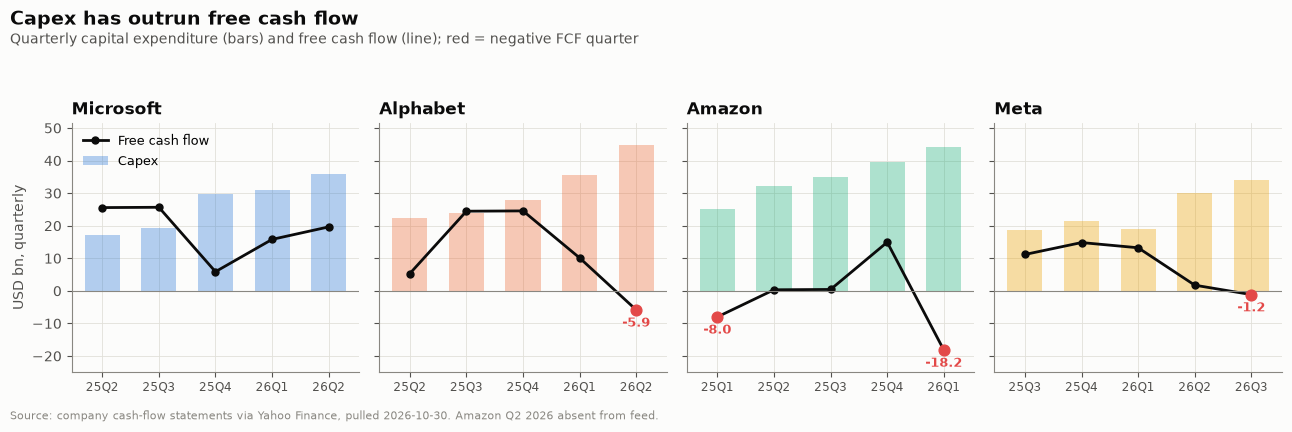

fig1 written; quarters per ticker: {'AMZN': datetime.date(2026, 3, 31), 'GOOGL': datetime.date(2026, 6, 30), 'META': datetime.date(2026, 9, 30), 'MSFT': datetime.date(2026, 6, 30)}


In [2]:
"""Figures 1, 3 (and 4 if BTOS available). Palette: one hue per entity, fixed order, no dual axes."""
import pandas as pd, numpy as np, matplotlib as mpl, matplotlib.pyplot as plt, pathlib, json

ROOT = pathlib.Path.cwd(); D = ROOT / "data"; F = ROOT / "figures"; F.mkdir(exist_ok=True)
META = json.load(open(D / "pull_meta.json"))["pulled_utc"][:10]

C = {"MSFT": "#2a78d6", "GOOGL": "#eb6834", "AMZN": "#1baf7a", "META": "#eda100",
     "CRWV": "#2a78d6", "NBIS": "#eb6834", "IREN": "#1baf7a", "APLD": "#eda100",
     "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781", "grid": "#e1e0d9", "neg": "#e34948"}
mpl.rcParams.update({"font.family": "sans-serif", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink2"], "xtick.color": C["ink2"],
                     "ytick.color": C["ink2"], "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                     "font.size": 10})
def qlabel(ts): ts = pd.Timestamp(ts); return f"{ts.year % 100:02d}Q{(ts.month - 1) // 3 + 1}"

# ---------- Figure 1: capex vs free cash flow, small multiples ----------
h = pd.read_csv(D / "hyperscaler_cashflow.csv", parse_dates=["quarter"])
h = h[h.quarter >= "2025-01-01"].dropna(subset=["capex", "fcf"])
NAMES = {"MSFT": "Microsoft", "GOOGL": "Alphabet", "AMZN": "Amazon", "META": "Meta"}
fig, axes = plt.subplots(1, 4, figsize=(13, 4.2), sharey=True)
ymax = h.capex.max() * 1.15
for ax, t in zip(axes, NAMES):
    d = h[h.ticker == t].reset_index(drop=True)
    x = np.arange(len(d))
    ax.bar(x, d.capex, width=0.62, color=C[t], alpha=0.35, linewidth=0, label="Capex")
    ax.plot(x, d.fcf, color=C["ink"], lw=2, marker="o", ms=5, label="Free cash flow")
    neg = d.fcf < 0
    ax.scatter(x[neg], d.fcf[neg], color=C["neg"], s=60, zorder=5)
    for i, v in zip(x[neg], d.fcf[neg]): ax.annotate(f"{v:.1f}", (i, v), xytext=(0, -12), textcoords="offset points",
                                                   ha="center", color=C["neg"], fontsize=9, fontweight="bold")
    ax.axhline(0, color=C["muted"], lw=0.8)
    ax.set_xticks(x); ax.set_xticklabels([qlabel(q) for q in d.quarter], fontsize=8.5)
    ax.set_title(NAMES[t], loc="left", color=C["ink"], fontweight="bold")
    ax.set_ylim(min(-25, h.fcf.min() * 1.2), ymax)
axes[0].set_ylabel("USD bn, quarterly")
axes[0].legend(frameon=False, loc="upper left", fontsize=9)
fig.suptitle("Capex has outrun free cash flow", x=0.01, ha="left", fontsize=14, fontweight="bold", color=C["ink"])
fig.text(0.01, 0.90, "Quarterly capital expenditure (bars) and free cash flow (line); red = negative FCF quarter",
         color=C["ink2"], fontsize=10)
fig.text(0.01, 0.005, f"Source: company cash-flow statements via Yahoo Finance, pulled {META}. Amazon Q2 2026 absent from feed.",
         color=C["muted"], fontsize=8)
fig.tight_layout(rect=(0, 0.03, 1, 0.88)); fig.savefig(F / "fig1_capex_vs_fcf.png", dpi=180); plt.show()
print("fig1 written; quarters per ticker:", h.groupby("ticker").quarter.max().dt.date.to_dict())



## 2. The money loop
`data/deals.csv` has one row per announced commitment with a source URL and a quote from that page. Rows marked `unverified` (anonymous-sourced press reports only, e.g. OpenAI→Oracle $300bn) or `conditional` (announced but contingent, e.g. the $35bn second tranche of Amazon's OpenAI investment) never enter the graph. Four editorial exclusions are stated in the code.

Cycle dollars are the sum of edge amounts that sit on at least one simple cycle. Edges with no public dollar figure (OpenAI's 10 GW Nvidia and 6 GW AMD commitments) are drawn dashed and carry zero weight, so the closed-loop share is a lower bound.

The money is circular. Of $610bn in announced commitments with a public dollar figure, $468bn sits on a closed loop in which a hyperscaler invests in a lab that commits to buy the hyperscaler's cloud. The largest loop runs Amazon to OpenAI to Microsoft to Anthropic and back to Amazon at $370bn, and the Microsoft and OpenAI pair alone carries $262bn.

For investors, the loop changes what revenue and backlog mean. When Microsoft invests in OpenAI and OpenAI commits $250bn to Azure, part of that commitment is Microsoft's own money coming back as revenue. The same applies to Amazon and Anthropic, where $13bn of investment sits against a $100bn AWS commitment. A backlog figure funded by the vendor deserves a lower multiple than one funded by outside customers, and the deal table lets a reader separate the two.

{'n_nodes': 13, 'n_edges': 24, 'n_cycles': 9, 'dollars_on_a_cycle_bn': 467.8, 'total_edge_dollars_bn': 610.4, 'share_on_cycle': 0.766}
                                              cycle  n_edges  unquantified_edges  min_quantified_edge_bn  sum_edges_bn
Microsoft → Anthropic → Amazon → OpenAI → Microsoft        4                   0                     5.0         370.0
                     Microsoft → OpenAI → Microsoft        2                   0                    11.8         261.8
      Nvidia → Anthropic → Amazon → OpenAI → Nvidia        4                   1                    10.0         125.0
                     Anthropic → Amazon → Anthropic        2                   0                    13.0         113.0
Microsoft → OpenAI → Nvidia → Anthropic → Microsoft        4                   1                    10.0          51.8
                  Microsoft → Anthropic → Microsoft        2                   0                     5.0          35.0
                           Nvidi

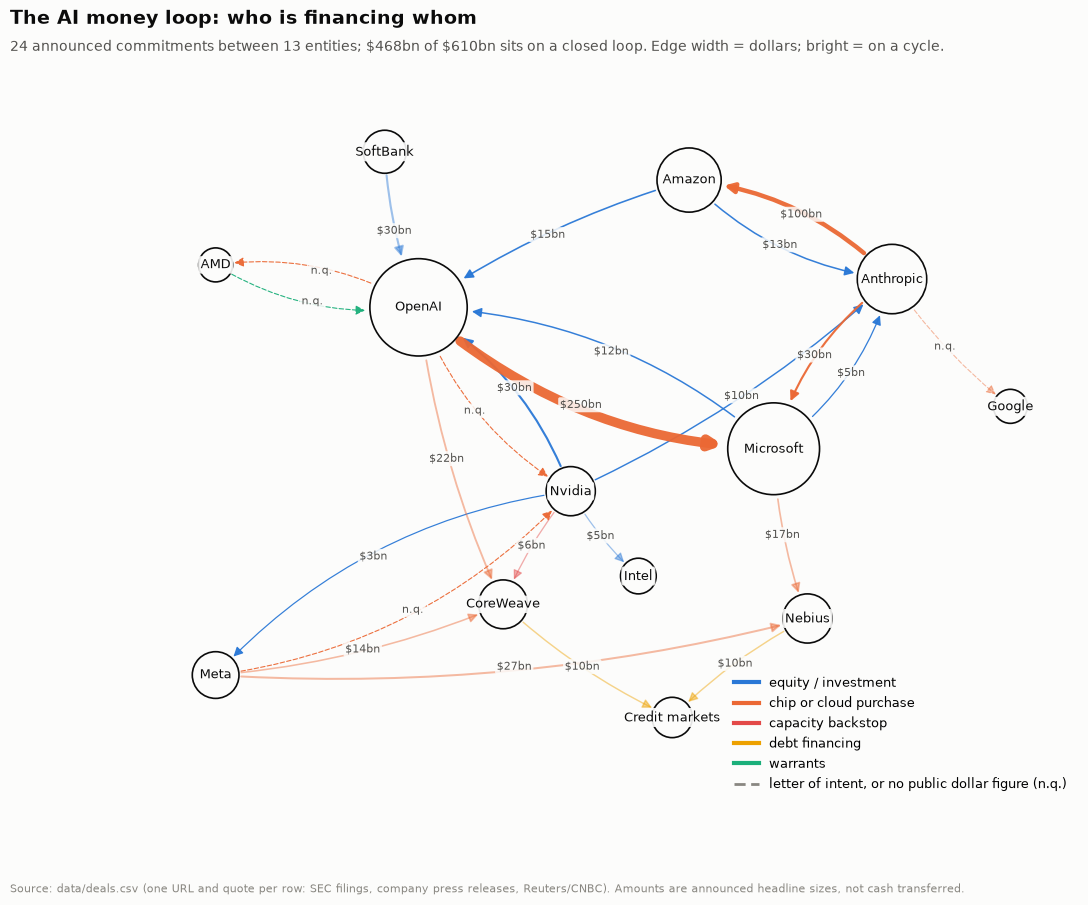

fig2 written


In [3]:
"""Figure 2: the AI money loop as a directed, dollar-weighted graph. Edges come only from data/deals.csv,
where every row carries a source URL and a quote. Computes closed-loop (cycle) dollars."""
import pandas as pd, numpy as np, networkx as nx, matplotlib.pyplot as plt, pathlib, sys
from matplotlib.patches import FancyArrowPatch

deals = pd.read_csv(D / "deals.csv")
deals = deals[~deals.type.isin(["capex_guidance", "capex_actual"])].copy()
deals = deals[deals.status.isin(["LOI", "committed", "funded"])]  # unverified rows never enter the graph
deals["amount_usd_bn"] = pd.to_numeric(deals.amount_usd_bn, errors="coerce")
deals = deals.dropna(subset=["from", "to"])
# Editorial exclusions, each stated in the notebook:
#  - the Sept 2025 $100bn Nvidia->OpenAI LOI was superseded by the $30bn that closed in the Feb 2026 round
#  - the Aug 2026 financing-platform MOU is a $500bn *third-party* capital target across six firms, not one funder's money
#  - the Meta FWP "indication of interest" from three cornerstone buyers is non-binding and not attributable to one buyer
#  - the July 2026 SK Group / Nvidia $500bn-plus partnership LOI runs both ways with no disclosed split
drop = ((deals["from"] == "Nvidia") & (deals["to"] == "OpenAI") & (deals.amount_usd_bn == 100)) \
     | deals["from"].str.contains(";") \
     | (deals["from"] == "SK Group")
deals = deals[~drop]
ALIAS = {"Amazon (AWS)": "Amazon", "Google Cloud": "Google", "bond investors": "Credit markets",
         "convertible investors": "Credit markets"}
deals["from"] = deals["from"].replace(ALIAS); deals["to"] = deals["to"].replace(ALIAS)
deals["quantified"] = deals.amount_usd_bn.notna()
deals["amount_usd_bn"] = deals.amount_usd_bn.fillna(0.0)

EDGE_COLOR = {"equity_investment": C["MSFT"], "purchase_commitment": C["GOOGL"], "cloud_contract": C["GOOGL"],
              "capacity_backstop": C["neg"], "debt_financing": C["META"], "warrant": C["AMZN"]}
EDGE_LABEL = {"equity_investment": "equity / investment", "purchase_commitment": "chip or cloud purchase",
              "cloud_contract": "chip or cloud purchase", "capacity_backstop": "capacity backstop",
              "debt_financing": "debt financing", "warrant": "warrants"}

G = nx.DiGraph()
for _, r in deals.iterrows():
    if G.has_edge(r["from"], r["to"]):
        e = G[r["from"]][r["to"]]; e["w"] += r.amount_usd_bn; e["types"].add(r.type); e["q"] = e["q"] or r.quantified
    else:
        G.add_edge(r["from"], r["to"], w=r.amount_usd_bn, types={r.type}, status=r.status, q=bool(r.quantified))

# Cycle accounting: dollars that sit on a closed loop. For each simple cycle, the loop's binding size is its min edge.
cycles = list(nx.simple_cycles(G))
cyc_rows = []
for cyc in cycles:
    edges = [(cyc[i], cyc[(i + 1) % len(cyc)]) for i in range(len(cyc))]
    ws = [G[a][b]["w"] for a, b in edges]
    nq = sum(not G[a][b]["q"] for a, b in edges)
    cyc_rows.append(dict(cycle=" → ".join(cyc + [cyc[0]]), n_edges=len(cyc), unquantified_edges=nq,
                         min_quantified_edge_bn=min([w for (a, b), w in zip(edges, ws) if G[a][b]["q"]] or [0]),
                         sum_edges_bn=sum(ws)))
cyc_df = pd.DataFrame(cyc_rows).sort_values("sum_edges_bn", ascending=False) if cyc_rows else pd.DataFrame()
cyc_df.to_csv(F / "table_cycles.csv", index=False)
on_cycle_edges = {e for cyc in cycles for e in zip(cyc, cyc[1:] + cyc[:1])}
loop_dollars = sum(G[a][b]["w"] for a, b in on_cycle_edges)
total_dollars = sum(d["w"] for _, _, d in G.edges(data=True))
summary = dict(n_nodes=G.number_of_nodes(), n_edges=G.number_of_edges(), n_cycles=len(cycles),
               dollars_on_a_cycle_bn=round(loop_dollars, 1), total_edge_dollars_bn=round(total_dollars, 1),
               share_on_cycle=round(loop_dollars / total_dollars, 3) if total_dollars else np.nan)
pd.Series(summary).to_csv(F / "table_loop_summary.csv")
print(summary); print(cyc_df.head(10).to_string(index=False) if len(cyc_df) else "no cycles")

# ---- draw ----
# Pinned positions; any node not listed falls back to a seeded spring layout
PIN = {"Nvidia": (0.0, -0.2), "OpenAI": (-0.45, 0.45), "Microsoft": (0.6, -0.05), "Anthropic": (0.95, 0.55),
       "Amazon": (0.35, 0.9), "SoftBank": (-0.55, 1.0), "AMD": (-1.05, 0.6), "Meta": (-1.05, -0.85),
       "CoreWeave": (-0.2, -0.6), "Intel": (0.2, -0.5), "Credit markets": (0.3, -1.0), "Nebius": (0.7, -0.65),
       "Google": (1.3, 0.1)}
fixed = [n for n in G if n in PIN]
pos = nx.spring_layout(G, seed=7, pos={n: PIN[n] for n in fixed} or None, fixed=fixed or None)
pos = {k: np.asarray(v, dtype=float) for k, v in pos.items()}
fig, ax = plt.subplots(figsize=(12, 9)); ax.axis("off")
flow_in = {n: sum(d["w"] for _, _, d in G.in_edges(n, data=True)) for n in G}
flow_out = {n: sum(d["w"] for _, _, d in G.out_edges(n, data=True)) for n in G}
size = {n: 600 + 12 * (flow_in[n] + flow_out[n]) for n in G}
wmax = max(d["w"] for _, _, d in G.edges(data=True))
for a, b, d in G.edges(data=True):
    t = sorted(d["types"])[0]; on = (a, b) in on_cycle_edges
    lw = 0.8 + 6 * d["w"] / wmax
    rad = 0.18 if G.has_edge(b, a) else 0.08
    dashed = d["status"] == "LOI" or not d["q"]
    arr = FancyArrowPatch(pos[a], pos[b], connectionstyle=f"arc3,rad={rad}", arrowstyle="-|>", mutation_scale=14,
                          lw=lw, color=EDGE_COLOR.get(t, C["muted"]), alpha=0.95 if on else 0.45,
                          shrinkA=np.sqrt(size[a]) * 0.55, shrinkB=np.sqrt(size[b]) * 0.55, zorder=1,
                          linestyle=(0, (4, 2)) if dashed else "-")
    ax.add_patch(arr)
    dx, dy = pos[b] - pos[a]
    mid = (pos[a] + pos[b]) / 2 + 0.5 * rad * np.array([dy, -dx])  # arc3 control point is mid + rad*(dy,-dx); curve passes halfway
    ax.text(*mid, f"${d['w']:.0f}bn" if d["q"] else "n.q.", fontsize=8, color=C["ink2"], ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.15", fc="#fcfcfb", ec="none", alpha=0.85), zorder=3)
nx.draw_networkx_nodes(G, pos, node_size=[size[n] for n in G], node_color="#fcfcfb", edgecolors=C["ink"], linewidths=1.2, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=9, font_color=C["ink"], ax=ax,
                        bbox=dict(boxstyle="round,pad=0.2", fc="#fcfcfb", ec="none", alpha=0.9))
ax.set_xlim(min(v[0] for v in pos.values()) - 0.2, max(v[0] for v in pos.values()) + 0.2)
ax.set_ylim(min(v[1] for v in pos.values()) - 0.3, max(v[1] for v in pos.values()) + 0.15)
from matplotlib.lines import Line2D
handles = [Line2D([0], [0], color=c, lw=3, label=EDGE_LABEL[t]) for t, c in EDGE_COLOR.items()
           if t in {tt for _, _, d in G.edges(data=True) for tt in d["types"]} and t != "cloud_contract"]
handles.append(Line2D([0], [0], color=C["muted"], lw=2, ls=(0, (4, 2)), label="letter of intent, or no public dollar figure (n.q.)"))
ax.legend(handles=handles, frameon=False, fontsize=9, loc="lower right")
fig.text(0.01, 0.975, "The AI money loop: who is financing whom", fontweight="bold", fontsize=14, color=C["ink"])
fig.text(0.01, 0.945, f"{summary['n_edges']} announced commitments between {summary['n_nodes']} entities; "
         f"\\${summary['dollars_on_a_cycle_bn']:.0f}bn of \\${summary['total_edge_dollars_bn']:.0f}bn sits on a closed loop. "
         "Edge width = dollars; bright = on a cycle.", color=C["ink2"], fontsize=10)
fig.text(0.01, 0.01, "Source: data/deals.csv (one URL and quote per row: SEC filings, company press releases, Reuters/CNBC). Amounts are announced headline sizes, not cash transferred.",
         color=C["muted"], fontsize=8)
fig.savefig(F / "fig2_money_loop.png", dpi=180, bbox_inches="tight"); plt.show()
print("fig2 written")


## 3. Neoclouds carry the debt
The borrowing has moved to the companies least able to carry it. CoreWeave, Nebius, IREN and Applied Digital hold $76bn of debt plus lease liabilities and all four reported negative operating income in their latest quarter. Their shares have given back most of their run: from the peak, CoreWeave is down 67%, IREN 66% and Nebius 40%, while Nvidia is down 11%, as of 29 October 2026.

CoreWeave carries $51.6bn of debt plus lease liabilities against $10.3bn of annualized revenue, a ratio of 5.0, and IREN carries 14.3 times. None of the four covers its interest from operations, and CoreWeave's interest expense ran $0.64bn in the June 2026 quarter. Nvidia's $6.3bn commitment to buy CoreWeave's unsold capacity through 2032 means the chip vendor is also the customer of last resort for its own chips.

Yahoo's 'Total Debt' line includes operating and finance leases; for CoreWeave at June 30, 2026 the 10-Q shows $35.1bn of borrowings and $16.5bn of lease liabilities. The figures below show debt plus leases vs. annualized revenue, interest coverage, and price paths since CoreWeave's listing.

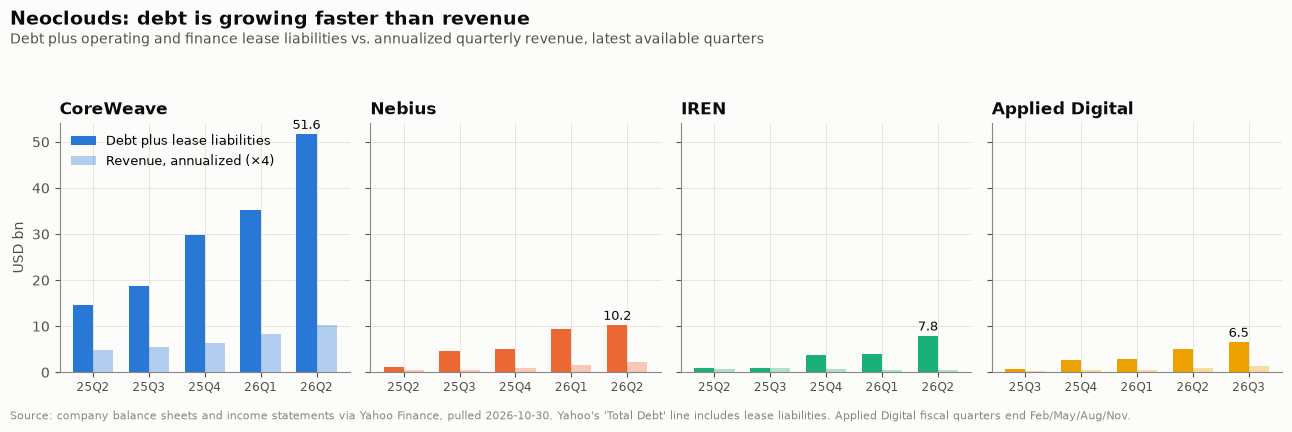

C:\Users\diazz\AppData\Local\Temp\ipykernel_67044\1717593097.py:27: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  "interest_coverage", "debt_to_annualized_rev"]].round(2)


ticker    quarter  total_debt  revenue  op_income  interest_expense  interest_coverage  debt_to_annualized_rev
  APLD 2026-08-31        6.48     0.34      -0.06              0.08              -0.81                    4.74
  CRWV 2026-06-30       51.61     2.58      -0.05              0.64              -0.08                    5.01
  IREN 2026-06-30        7.84     0.14      -0.14              0.02              -5.75                   14.28
  NBIS 2026-06-30       10.17     0.58      -0.18              0.12              -1.48                    4.37


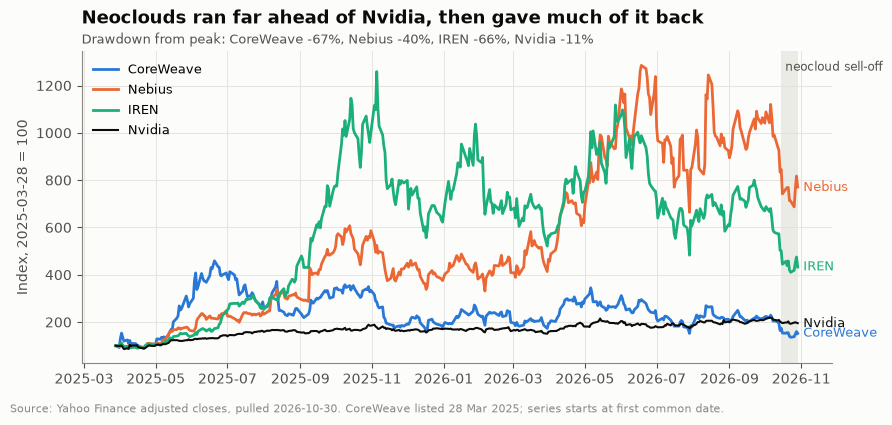

figures written


In [4]:
# ---------- Figure 3: neocloud debt vs revenue ----------
n = pd.read_csv(D / "neocloud_financials.csv", parse_dates=["quarter"]).dropna(subset=["total_debt"])
NEO = {"CRWV": "CoreWeave", "NBIS": "Nebius", "IREN": "IREN", "APLD": "Applied Digital"}
fig, axes = plt.subplots(1, 4, figsize=(13, 4.2), sharey=True)
for ax, t in zip(axes, NEO):
    d = n[n.ticker == t].reset_index(drop=True); x = np.arange(len(d))
    ax.bar(x - 0.18, d.total_debt, width=0.36, color=C[t], linewidth=0, label="Debt plus lease liabilities")
    ax.bar(x + 0.18, d.revenue * 4, width=0.36, color=C[t], alpha=0.35, linewidth=0, label="Revenue, annualized (×4)")
    ax.set_xticks(x); ax.set_xticklabels([qlabel(q) for q in d.quarter], fontsize=8.5)
    ax.set_title(NEO[t], loc="left", color=C["ink"], fontweight="bold")
    last = d.iloc[-1]
    ax.annotate(f"{last.total_debt:.1f}", (x[-1] - 0.18, last.total_debt), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=9, color=C["ink"])
axes[0].set_ylabel("USD bn"); axes[0].legend(frameon=False, loc="upper left", fontsize=9)
fig.suptitle("Neoclouds: debt is growing faster than revenue", x=0.01, ha="left", fontsize=14, fontweight="bold", color=C["ink"])
fig.text(0.01, 0.90, "Debt plus operating and finance lease liabilities vs. annualized quarterly revenue, latest available quarters",
         color=C["ink2"], fontsize=10)
fig.text(0.01, 0.005, f"Source: company balance sheets and income statements via Yahoo Finance, pulled {META}. Yahoo's 'Total Debt' line includes lease liabilities. "
         "Applied Digital fiscal quarters end Feb/May/Aug/Nov.", color=C["muted"], fontsize=8)
fig.tight_layout(rect=(0, 0.03, 1, 0.88)); fig.savefig(F / "fig3_neocloud_debt.png", dpi=180); plt.show()

# Coverage table (interest coverage = operating income / interest expense)
cov = n.copy()
cov["interest_coverage"] = cov.op_income / cov.interest_expense
cov["debt_to_annualized_rev"] = cov.total_debt / (cov.revenue * 4)
tbl = cov.groupby("ticker").tail(1)[["ticker", "quarter", "total_debt", "revenue", "op_income", "interest_expense",
                                      "interest_coverage", "debt_to_annualized_rev"]].round(2)
tbl.to_csv(F / "table_neocloud_coverage.csv", index=False); print(tbl.to_string(index=False))

# ---------- Figure 3b: neocloud + Nvidia price paths since Jan 2025 ----------
px = pd.read_csv(D / "prices.csv", parse_dates=["Date"]).set_index("Date")
idx = px[["CRWV", "NBIS", "IREN", "NVDA"]].dropna()
idx = idx / idx.iloc[0] * 100
fig, ax = plt.subplots(figsize=(9, 4.2))
LBL = {**NEO, "NVDA": "Nvidia"}
for t, c in [("CRWV", C["CRWV"]), ("NBIS", C["NBIS"]), ("IREN", C["IREN"]), ("NVDA", C["ink"])]:
    ax.plot(idx.index, idx[t], lw=2 if t != "NVDA" else 1.5, color=c, label=LBL[t])
    ax.annotate(LBL[t], (idx.index[-1], idx[t].iloc[-1]), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=9, color=c)
ax.axvspan(pd.Timestamp("2026-10-15"), idx.index[-1], color=C["grid"], alpha=0.6, lw=0)
ax.text(pd.Timestamp("2026-10-15"), ax.get_ylim()[1] * 0.97, " neocloud sell-off", fontsize=8.5, color=C["ink2"], va="top")
ax.set_ylabel(f"Index, {idx.index[0].date()} = 100"); ax.legend(frameon=False, fontsize=9, loc="upper left")
dd = (idx / idx.cummax() - 1).iloc[-1] * 100
ax.set_title("Neoclouds ran far ahead of Nvidia, then gave much of it back", loc="left", fontweight="bold", fontsize=13,
             color=C["ink"], pad=20)
ax.text(0, 1.015, "Drawdown from peak: " + ", ".join(f"{LBL[t]} {dd[t]:.0f}%" for t in ["CRWV", "NBIS", "IREN", "NVDA"]),
        transform=ax.transAxes, fontsize=9, color=C["ink2"], va="bottom")
dd.round(1).to_csv(F / "table_drawdowns.csv")
fig.text(0.01, 0.005, f"Source: Yahoo Finance adjusted closes, pulled {META}. CoreWeave listed 28 Mar 2025; series starts at first common date.",
         color=C["muted"], fontsize=8)
fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(F / "fig3b_neocloud_prices.png", dpi=180); plt.show()
print("figures written")


## 4. Is anyone paying at the end of the chain?
Census BTOS, national workbook, downloaded directly from census.gov. The series starts Nov 2025, when the question was reworded to 'any business function'. The current question text refers to 'Super Intelligence or SI (formerly referred to as Artificial Intelligence or AI)'.

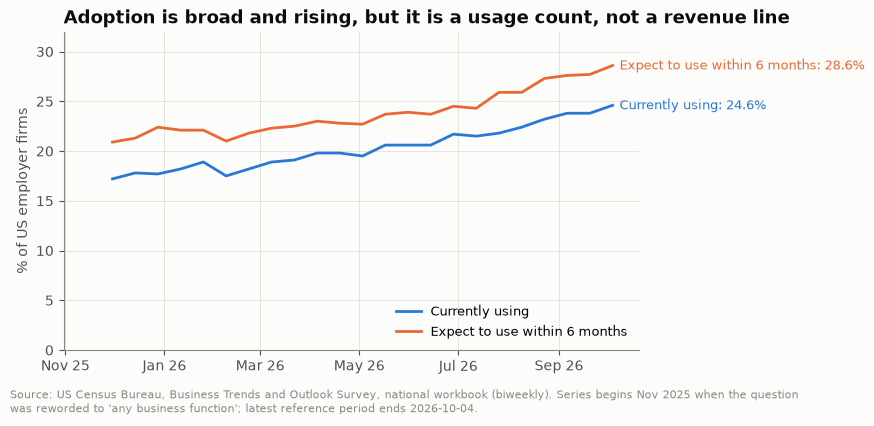

     smpdt   pct    ref_end
21  202619  23.8 2026-09-06
22  202620  23.8 2026-09-20
23  202621  24.6 2026-10-04
first 2025-11-16 17.3


In [5]:
"""Census BTOS: share of US employer firms using AI in the last two weeks (national). Figure 4."""
import pandas as pd, numpy as np, matplotlib.pyplot as plt, pathlib, sys

raw = pathlib.Path.cwd() / "raw" / "National.xlsx"
est = pd.read_excel(raw, sheet_name="Response Estimates")
dates = pd.read_excel(raw, sheet_name="Collection and Reference Dates")
dates = dates.rename(columns={"Smpdt": "smpdt", "Ref End": "ref_end"})[["smpdt", "ref_end"]].dropna()
dates["smpdt"] = dates.smpdt.astype(int)

def series(qid, ans="Yes"):
    row = est[(est["Question ID"] == qid) & (est["Answer"] == ans)].iloc[0]
    s = row.drop(["Question ID", "Question", "Answer ID", "Answer"])
    s = s.replace(".", np.nan).astype(str).str.rstrip("%").replace("nan", np.nan).astype(float)
    s.index = s.index.astype(int)
    out = pd.DataFrame({"smpdt": s.index, "pct": s.values}).merge(dates, on="smpdt").dropna()
    return out.sort_values("ref_end").reset_index(drop=True)

use = series(7); plan = series(24)
use.to_csv(D / "btos_ai_use.csv", index=False); plan.to_csv(D / "btos_ai_plan.csv", index=False)
BREAK = pd.Timestamp("2025-11-17")  # question broadened from "producing goods or services" to "any business function"

fig, ax = plt.subplots(figsize=(9, 4.2))
for d, c, lbl in [(use, C["MSFT"], "Currently using"), (plan, C["GOOGL"], "Expect to use within 6 months")]:
    pre, post = d[d.ref_end < BREAK], d[d.ref_end >= BREAK]
    ax.plot(pre.ref_end, pre.pct, color=c, lw=2, label=lbl)
    ax.plot(post.ref_end, post.pct, color=c, lw=2)
    ax.annotate(f"{lbl}: {d.pct.iloc[-1]:.1f}%", (d.ref_end.iloc[-1], d.pct.iloc[-1]), xytext=(5, 0),
                textcoords="offset points", va="center", fontsize=9, color=c)
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax.set_ylabel("% of US employer firms"); ax.set_ylim(0, 32)
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.set_title("Adoption is broad and rising, but it is a usage count, not a revenue line", loc="left",
             fontweight="bold", fontsize=13, color=C["ink"])
fig.text(0.01, 0.005, "Source: US Census Bureau, Business Trends and Outlook Survey, national workbook (biweekly). Series begins Nov 2025 when the question\n"
         f"was reworded to 'any business function'; latest reference period ends {use.ref_end.iloc[-1].date()}.",
         color=C["muted"], fontsize=8)
fig.tight_layout(rect=(0, 0.06, 0.97, 1)); fig.savefig(F / "fig4_btos_adoption.png", dpi=180); plt.show()
print(use.tail(3)); print("first", use.ref_end.iloc[0].date(), use.pct.iloc[0])


## 5. Discussion

### Why the topic matters in financial markets
The spend has outrun the cash that funds it, the borrowing has moved to the companies least able to carry it, and the money is circular. Alphabet, Microsoft and Meta reported $131.5bn of capital expenditure between them for the third quarter of 2026, three of the four hyperscalers have printed a negative free-cash-flow quarter since 2025, and $468bn of $610bn in announced commitments sits on a closed loop. These companies are the largest weights in the S&P 500, so the question of whether this spend earns a return is a question about the index itself.

### Relevance to investors and regulators
For investors, a backlog funded by the vendor's own investment deserves a lower multiple than one funded by outside customers, and the neocloud balance sheets set the credit question: $76bn of debt plus leases, none of it covered by operating income.

For regulators, the record shows three disclosure gaps. Headline commitments are ceilings: Amazon's $50bn OpenAI investment is $15bn firm and $35bn conditional, and Meta's $14.2bn CoreWeave contract is an "up to" figure. Common data feeds blur the balance sheet: Yahoo's "Total Debt" line for CoreWeave includes $16.5bn of lease liabilities that the 10-Q reports separately from $35.1bn of borrowings. Segment reporting shifts under the analysis: Microsoft retired its Intelligent Cloud segment in the September 2026 quarter and printed Azure revenue in dollars, $33.2bn, for the first time. Vendor financing, circular commitments and related-party capacity guarantees are the exposures that disclosure rules exist to surface, and most of these are visible only by reading the filings themselves.

### How the topic relates to the course
Module 3 covers the risk and return of portfolios and the S&P 500. Portfolio variance is a weighted sum of covariances, so what matters for an index holder is not how many names they own but how much those names move together. Microsoft, Alphabet, Amazon, Meta and Nvidia are five of the largest index weights, and the deal graph shows their cash flows are tied: the same dollars count as Microsoft's investment, OpenAI's spending and Nvidia's sales. That raises the covariance term, so an S&P 500 holder is less diversified across these five than the count suggests.

The neocloud price paths show the levered end of the same bet. Indexed to CoreWeave's listing in March 2025, IREN and Nebius rose above 1,000 before giving back most of the gain, while Nvidia moved inside a far narrower band. Same factor, different leverage, different variance.

The break-even calculator in the dashboard turns the capex into a required return. At a $735bn annual run-rate, a five-year useful life, a 10% required return and a 30% operating margin, the AI business must add $735bn of revenue a year to stand still. The four cloud and ad segments added $136bn over their latest four quarters. The gap is the expected-return assumption the market is making, and the width of the outcomes around it is the risk the module asks us to price.

### How the data ties to the discussion
Five datasets carry the argument, each pulled or hand-entered in this notebook with its source and pull date.

| Dataset | What it shows | Limitations |
| --- | --- | --- |
| Hyperscaler cash flows (Yahoo Finance via yfinance) | Capex has outrun free cash flow; three of four printed a negative FCF quarter since 2025 | Yahoo labels are not GAAP lines. Meta's Q3 2026 capex is $33.9bn on Yahoo and $34.9bn in the 8-K; the gap is finance-lease principal. Amazon's Q2 2026 is missing from the feed |
| Deal table (`data/deals.csv`, 50 rows, one URL and quote each) | $468bn of $610bn in announced commitments sits on a closed loop, 77% | Amounts are headline sizes, not cash transferred. Commitments with no dollar figure carry zero weight, so the loop share is a lower bound. Anonymous-sourced reports such as OpenAI to Oracle at $300bn stay out |
| Neocloud financials (Yahoo Finance) | Debt plus leases of $76bn across four companies, all with negative operating income | Yahoo's "Total Debt" includes operating leases; CoreWeave's $51.6bn splits into $35.1bn of borrowings and $16.5bn of leases per the 10-Q |
| Census BTOS, national workbook | AI use among US employer firms rose from 17.3% in November 2025 to 24.6% in October 2026; 28.6% expect to use it within six months | Counts firms, not dollars. The question was reworded in November 2025, so earlier readings do not compare |
| Segment revenue (`data/segment_revenue.csv`, 8-K exhibits) | New segment revenue per dollar of capex over the latest four quarters: Amazon 0.17, Alphabet 0.21, Microsoft 0.27, Meta 0.49 | Capex is company-wide, segment revenue is one segment, and both include non-AI activity. Meta's Family of Apps operating income fell $1.9bn over the window. Microsoft's series stops at June 2026 when it retired the Intelligent Cloud segment |

Each number in the text above comes from one of these rows, and each row links to the filing or release it came from.